# Customer Churn Analysis-Exploratory Data Analysis (EDA)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


####  Dataset Info: Sample dataset containing E-Commerce customer information and details bout customer purchasing behaviour, engagement, and churn patterns. 

### 1 Load the data file

In [2]:
ch=pd.read_csv(r"C:\Users\user\Downloads\E-commerce_Customer_Churn_2026.csv")

In [3]:
ch

,churn_id,customer_id,customer_segment,customer_country,customer_city,is_churned,churn_flag,churn_date,days_since_churn,churn_reason,...,customer_retention_cost_usd,recovery_revenue_usd,dataset_year,churn_rate_indicator,customer_value_category,churn_risk_category,churn_revenue_impact_usd,customer_health_score,customer_health_category,retention_probability
0,CHURN-000001,CUST-020712,Consumer,Australia,Brisbane,Yes,1,2026-05-18 00:00:00,23,Found Alternative,...,29.33,346.60,2026,Medium,High Value,Medium,10351.348,75,Good,0.10
1,CHURN-000002,CUST-044206,Small Business,Saudi Arabia,Khobar,No,0,Not Applicable,0,Not Applicable,...,49.22,403.14,2026,Low,High Value,Low,0.000,100,Excellent,0.66
2,CHURN-000003,CUST-024093,Small Business,Mexico,Leon,No,0,Not Applicable,0,Not Applicable,...,198.06,4.20,2026,Low,High Value,Low,0.000,100,Excellent,0.76
3,CHURN-000004,CUST-037777,Enterprise,Saudi Arabia,Jeddah,No,0,Not Applicable,0,Not Applicable,...,190.31,222.46,2026,Low,High Value,Very Low,0.000,100,Excellent,0.98
4,CHURN-000005,CUST-016248,Premium,Pakistan,Multan,Yes,1,2026-05-28 00:00:00,7,Poor Customer Service,...,26.49,489.02,2026,Medium,High Value,Medium,14212.088,80,Good,0.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,CHURN-049996,CUST-033392,Consumer,Japan,Kawasaki,Yes,1,2026-04-26 00:00:00,111,Poor Customer Service,...,161.81,339.11,2026,Medium,High Value,Medium,12099.240,100,Excellent,0.10
49996,CHURN-049997,CUST-034467,Consumer,Pakistan,Gujranwala,No,0,Not Applicable,0,Not Applicable,...,101.13,29.87,2026,Low,High Value,Low,0.000,55,Fair,0.60
49997,CHURN-049998,CUST-048383,Consumer,United Kingdom,Edinburgh,No,0,Not Applicable,0,Not Applicable,...,85.95,311.56,2026,Low,High Value,Low,0.000,100,Excellent,0.75
49998,CHURN-049999,CUST-014737,Consumer,Spain,Malaga,Yes,1,2026-11-18 00:00:00,164,Found Alternative,...,115.02,198.19,2026,Medium,High Value,High,17454.696,65,Good,0.10


##### check the various attributes of data like shape(rows and cols),columns,datatypes

In [4]:
ch.shape

(50000, 48)

In [5]:
ch.size

2400000

In [6]:
ch.columns

Index(['churn_id', 'customer_id', 'customer_segment', 'customer_country',
       'customer_city', 'is_churned', 'churn_flag', 'churn_date',
       'days_since_churn', 'churn_reason', 'churn_category',
       'churn_risk_score', 'churn_probability', 'subscription_type',
       'customer_age_months', 'total_spend_usd', 'avg_order_value_usd',
       'num_purchases', 'satisfaction_score', 'satisfaction_level',
       'support_tickets', 'returns_count', 'days_since_last_purchase',
       'customer_lifetime_value_usd', 'engagement_level', 'prevention_method',
       'support_interactions', 'last_support_channel', 'feedback_score',
       'loyalty_score', 'marketing_emails_sent', 'marketing_emails_opened',
       'marketing_emails_clicked', 'marketing_conversions',
       'social_media_engagement', 'referral_count', 'is_high_risk_customer',
       'predicted_churn', 'customer_retention_cost_usd',
       'recovery_revenue_usd', 'dataset_year', 'churn_rate_indicator',
       'customer_value_cat

In [7]:
# Checking the data types of all the columns
ch.dtypes

churn_id                        object
customer_id                     object
customer_segment                object
customer_country                object
customer_city                   object
is_churned                      object
churn_flag                       int64
churn_date                      object
days_since_churn                 int64
churn_reason                    object
churn_category                  object
churn_risk_score                 int64
churn_probability              float64
subscription_type               object
customer_age_months              int64
total_spend_usd                float64
avg_order_value_usd            float64
num_purchases                    int64
satisfaction_score               int64
satisfaction_level              object
support_tickets                  int64
returns_count                    int64
days_since_last_purchase         int64
customer_lifetime_value_usd    float64
engagement_level                object
prevention_method        

In [8]:
# Check the descriptive statistics of numeric variables
ch.describe()

,churn_flag,days_since_churn,churn_risk_score,churn_probability,customer_age_months,total_spend_usd,avg_order_value_usd,num_purchases,satisfaction_score,support_tickets,...,marketing_emails_opened,marketing_emails_clicked,marketing_conversions,referral_count,customer_retention_cost_usd,recovery_revenue_usd,dataset_year,churn_revenue_impact_usd,customer_health_score,retention_probability
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.0,50000.000000,50000.000000,50000.000000
mean,0.413060,37.193620,41.159080,0.411591,30.134580,25039.361048,2263.123812,24.505700,3.008040,9.405480,...,12.211740,12.25672,3.118120,9.493440,99.903609,249.263203,2026.0,4135.546160,88.604100,0.447838
std,0.492388,55.352953,24.709309,0.247093,16.893094,14401.590909,4797.349786,14.433401,1.420569,5.763646,...,11.100082,11.13755,2.845841,5.768815,57.774781,144.579983,0.0,6158.312439,17.484367,0.332232
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.720000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.020000,2026.0,0.000000,25.000000,0.020000
25%,0.000000,0.000000,22.000000,0.220000,16.000000,12578.125000,469.940000,12.000000,2.000000,4.000000,...,3.000000,3.00000,1.000000,4.000000,49.767500,124.177500,2026.0,0.000000,80.000000,0.100000
50%,0.000000,0.000000,40.000000,0.400000,30.000000,25034.390000,982.480000,24.000000,3.000000,9.000000,...,9.000000,9.00000,2.000000,10.000000,100.105000,248.910000,2026.0,0.000000,100.000000,0.460000
75%,1.000000,72.000000,59.000000,0.590000,45.000000,37579.255000,1912.195000,37.000000,4.000000,14.000000,...,19.000000,19.00000,5.000000,14.000000,149.802500,374.232500,2026.0,7923.600000,100.000000,0.750000
max,1.000000,179.000000,100.000000,1.000000,59.000000,49998.300000,49980.820000,49.000000,5.000000,19.000000,...,49.000000,49.00000,9.000000,19.000000,200.000000,500.000000,2026.0,19999.320000,100.000000,1.000000


###
The dataset contains 50,000 customer records.

The average customer churn rate is approximately 41.31%.

The average customer age is around 30 months.

Average total customer spending is approximately $25,039.36.

The average churn risk score is 41.16 out of 100.

The average customer satisfaction score is 3.01

Customers have raised an average of approximately 9.41 support tickets.

The average customer health score is 88.60, while the average retention probability is 44.78%.

The average churn revenue impact is approximately $4,135.55.

### 2 Data Cleaning

In [9]:
ch.duplicated().sum()

np.int64(0)

In [10]:
ch.isnull().sum()

churn_id                           0
customer_id                        0
customer_segment                   0
customer_country                   0
customer_city                      0
is_churned                         0
churn_flag                         0
churn_date                         0
days_since_churn                   0
churn_reason                       0
churn_category                     0
churn_risk_score                   0
churn_probability                  0
subscription_type              13142
customer_age_months                0
total_spend_usd                    0
avg_order_value_usd                0
num_purchases                      0
satisfaction_score                 0
satisfaction_level                 0
support_tickets                    0
returns_count                      0
days_since_last_purchase           0
customer_lifetime_value_usd        0
engagement_level                   0
prevention_method              36874
support_interactions               0
l

##### 
As we can see, there are missing values in 3 columns: subscription_type, prevention_method, and 
social_media_engagement. Among these, prevention_method has the highest number of missing values (36,874), followed by 
social_media_engagement (15,004) and subscription_type (13,142). These missing values need to be handled during data 
cleaning before proceeding with further analysis.

In [11]:
### Missing values Treatment
ch["subscription_type"]=ch["subscription_type"].fillna("unknown")
ch["prevention_method"]=ch["prevention_method"].fillna("Not Recorded")
ch["social_media_engagement"]=ch["social_media_engagement"].fillna("unknown")

In [12]:
ch.isnull().sum()

churn_id                       0
customer_id                    0
customer_segment               0
customer_country               0
customer_city                  0
is_churned                     0
churn_flag                     0
churn_date                     0
days_since_churn               0
churn_reason                   0
churn_category                 0
churn_risk_score               0
churn_probability              0
subscription_type              0
customer_age_months            0
total_spend_usd                0
avg_order_value_usd            0
num_purchases                  0
satisfaction_score             0
satisfaction_level             0
support_tickets                0
returns_count                  0
days_since_last_purchase       0
customer_lifetime_value_usd    0
engagement_level               0
prevention_method              0
support_interactions           0
last_support_channel           0
feedback_score                 0
loyalty_score                  0
marketing_

## 3 Data Exploration

### 3.1 Univariate Analysis

### Customer Churn Distribution
To understand how many customers have left the company and how many customers are still active.

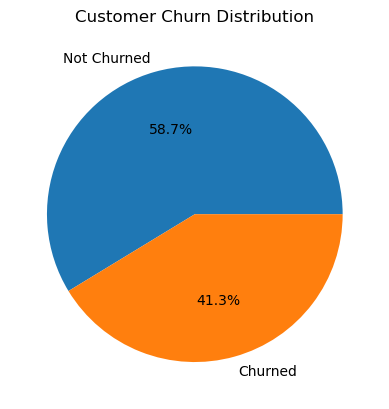

In [13]:
ch['is_churned'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    labels=['Not Churned', 'Churned']
)

plt.title('Customer Churn Distribution')
plt.ylabel('')
plt.show()

#####  Most customers (58.7%) are still with the company, while 41.3% have left the company.

### Customer Segment Distribution
To identify the customer segment with the highest and lowest number of customers.

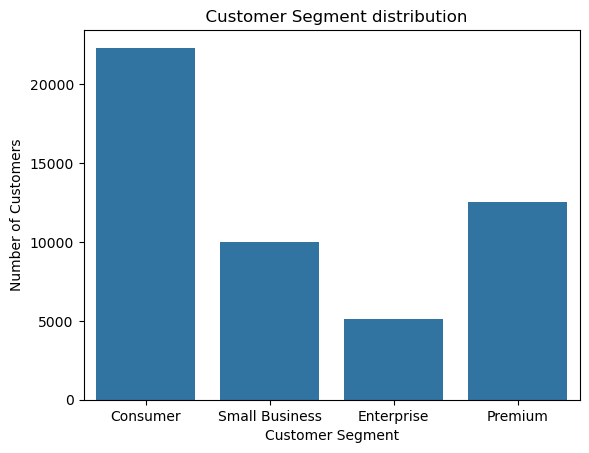

In [14]:
sns.countplot(data=ch, x='customer_segment',)
plt.title('  Customer Segment distribution')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.show()

#### Consumer has the highest number of customers, followed by Premium and Small Business, while Enterprise has the lowest number of customers.

### Customer Country Distribution
To identify the top 5 countries with the highest number of customers.

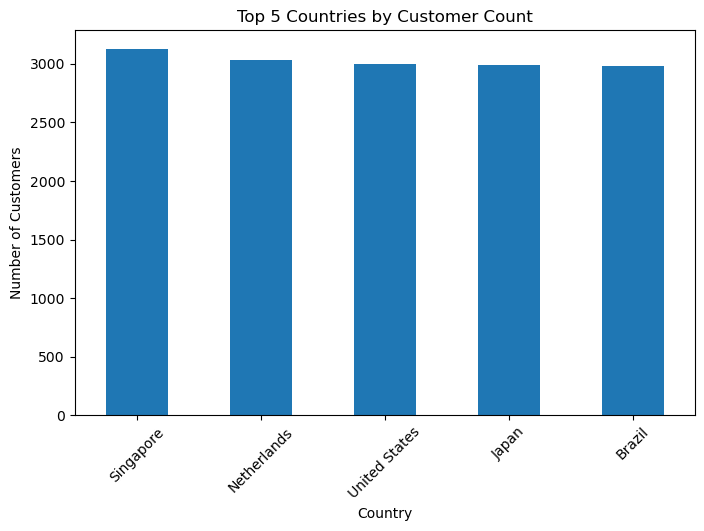

In [15]:
top_5_countries = ch['customer_country'].value_counts().head(5)

plt.figure(figsize=(8,5))

top_5_countries.plot(kind='bar',)


plt.title('Top 5 Countries by Customer Count')
plt.xlabel('Country')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)

plt.show()

##### Singapore has the highest number of customers among the top 5 countries.

### Churn Reason Analysis
To identify the most common reasons why customers leave the company.

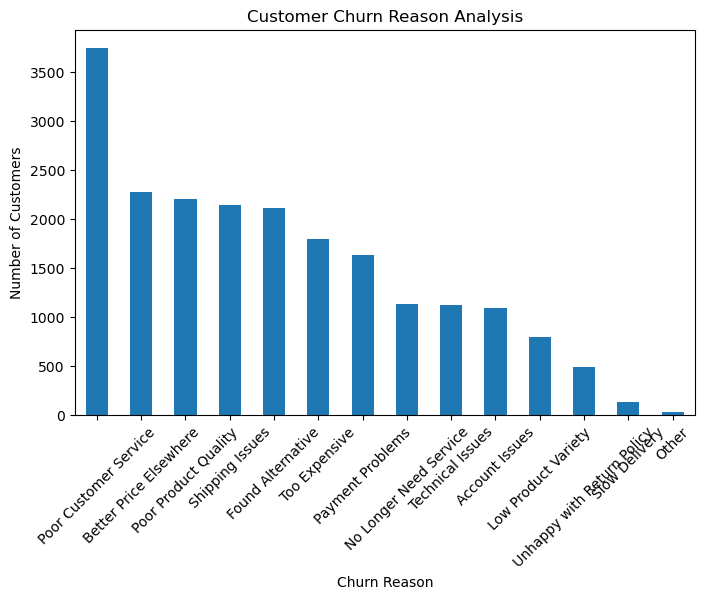

In [16]:
churn_reasons = ch[ch['churn_reason'] != 'Not Applicable']

churn_reasons['churn_reason'].value_counts().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Customer Churn Reason Analysis')
plt.xlabel('Churn Reason')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

##### Poor Customer Service is the most common reason for customer churn, followed by other reasons such as Better Price Elsewhere, Poor Product Quality, and Found Alternatives.

### 3.2 Bivariate Analysis

### Customer Segment vs Churn
To compare the number of churned and active customers across different customer segments.

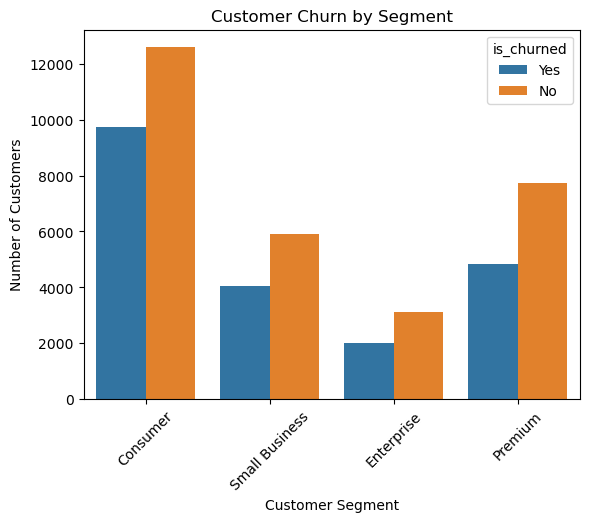

In [17]:
sns.countplot(data=ch, x='customer_segment', hue='is_churned')

plt.title('Customer Churn by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

##### All customer segments have more active customers than churned customers. The Consumer segment has the highest number of both active and churned customers.

### Customer Churn by Subscription Type
To identify which subscription type has the highest number of active and churned customers.

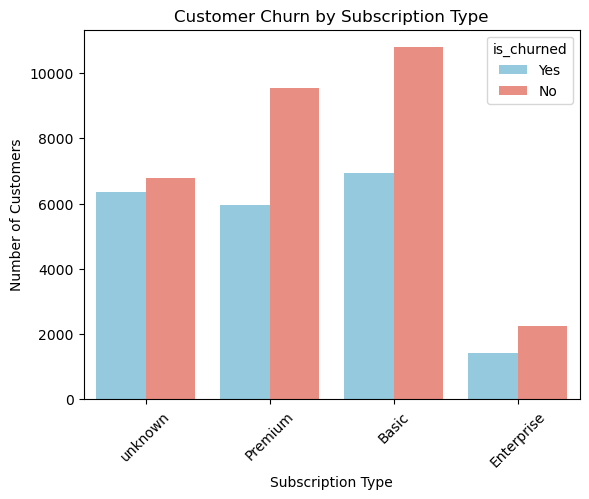

In [18]:
sns.countplot(data=ch, x='subscription_type', hue='is_churned',palette=["skyblue","salmon"])
plt.title('Customer Churn by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

##### 

The Basic subscription type has the highest number of customers and also the highest number of churned customers.

### Customer Churn by Satisfaction Level 
To understand the relationship between customer satisfaction level and customer churn.

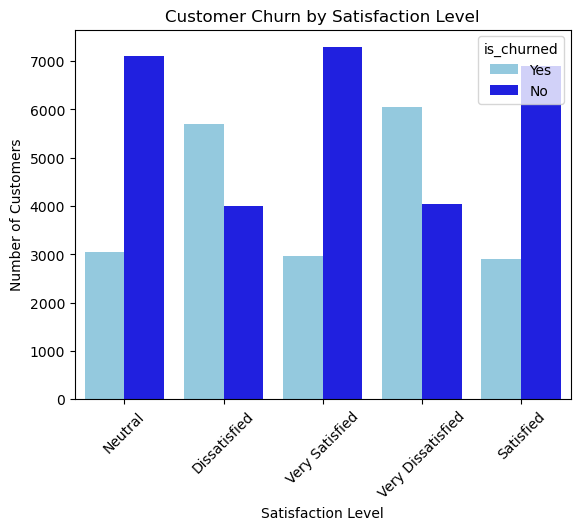

In [19]:
sns.countplot(data=ch, x='satisfaction_level',
              hue='is_churned',
              palette=["skyblue","blue"])

plt.title('Customer Churn by Satisfaction Level')
plt.xlabel('Satisfaction Level')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

#### Dissatisfied and Very Dissatisfied customers show higher churn counts, while satisfied customers have more active customers.


### Customer Churn by Support Tickets
To understand the relationship between customer support tickets and customer churn.

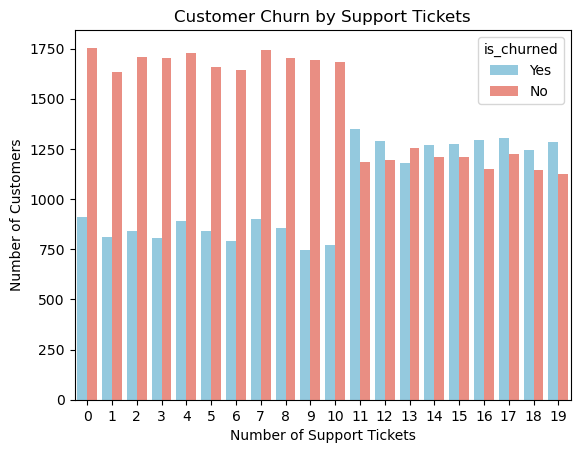

In [20]:
sns.countplot(data=ch, x='support_tickets',
              hue='is_churned',
              palette=['skyblue', 'salmon'])

plt.title('Customer Churn by Support Tickets')
plt.xlabel('Number of Support Tickets')
plt.ylabel('Number of Customers')
plt.show()

#### Customers raising 11 or more support tickets show a higher number of churn cases.

### Churn Rate by Support Tickets
To identify how the number of support tickets is related to customer churn rate.

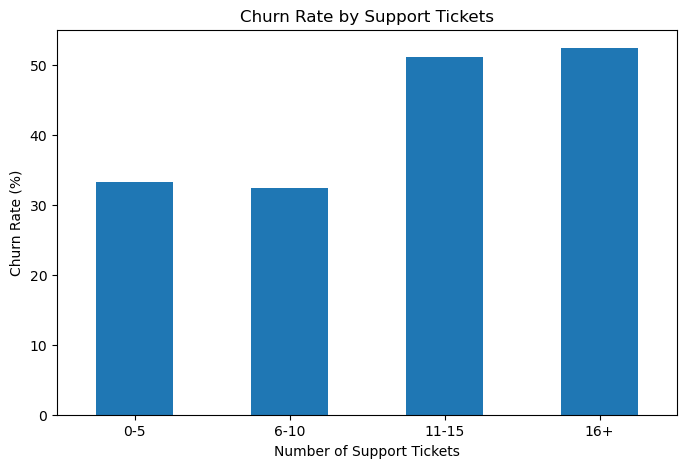

In [21]:
ch['ticket_group'] = pd.cut(
    ch['support_tickets'],
    bins=[-1, 5, 10, 15, float('inf')],
    labels=['0-5', '6-10', '11-15', '16+']
)

ticket_churn = ch.groupby('ticket_group', observed=True)['churn_flag'].mean() * 100

ticket_churn.plot(kind='bar', figsize=(8,5))

plt.title('Churn Rate by Support Tickets')
plt.xlabel('Number of Support Tickets')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

#### Customers with 11–15 support tickets show a higher churn rate of approximately 49%.

### Customer Churn by Churn Risk Score
To understand how churn risk scores differ between churned and non-churned customers

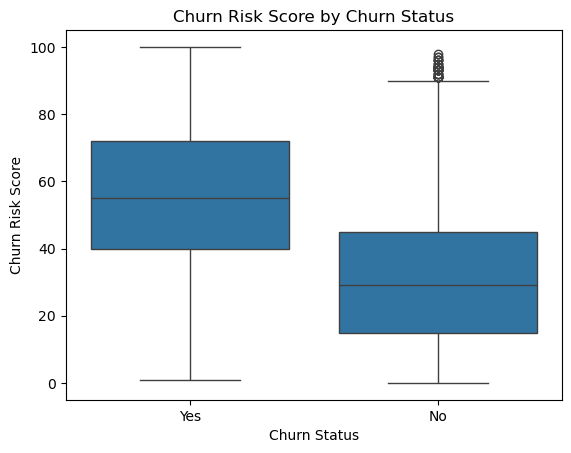

In [22]:
sns.boxplot(data=ch, x='is_churned', y='churn_risk_score')

plt.title('Churn Risk Score by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Churn Risk Score')
plt.show()

#### Customers with higher churn risk scores tend to show a greater likelihood of churn, indicating that churn risk scores can help identify customers who may leave the company.

### churn rate by customer segment

In [23]:
ch.groupby('customer_segment')['churn_flag'].mean() * 100

customer_segment
Consumer          43.642473
Enterprise        39.302416
Premium           38.503780
Small Business    40.639086
Name: churn_flag, dtype: float64

#### Consumer segment have the highest churn rate (43.64%),

### Churn Rate by Subscription Type

In [24]:
ch[ch['subscription_type'].str.lower() != 'unknown'].groupby('subscription_type')['churn_flag'].mean() * 100

subscription_type
Basic         39.119639
Enterprise    38.990450
Premium       38.428230
Name: churn_flag, dtype: float64

#### The Basic subscription type has the highest churn rate (39.11%),The missing values in subscription type were filled with 'Unknown'. These Unknown values were excluded from the churn rate calculation because their actual subscription type is not available. 

### 3.3 Multivariate Analysis

### Customer Churn by Satisfaction Level and Subscription Type
To understand how customer churn varies across different satisfaction levels and subscription types.

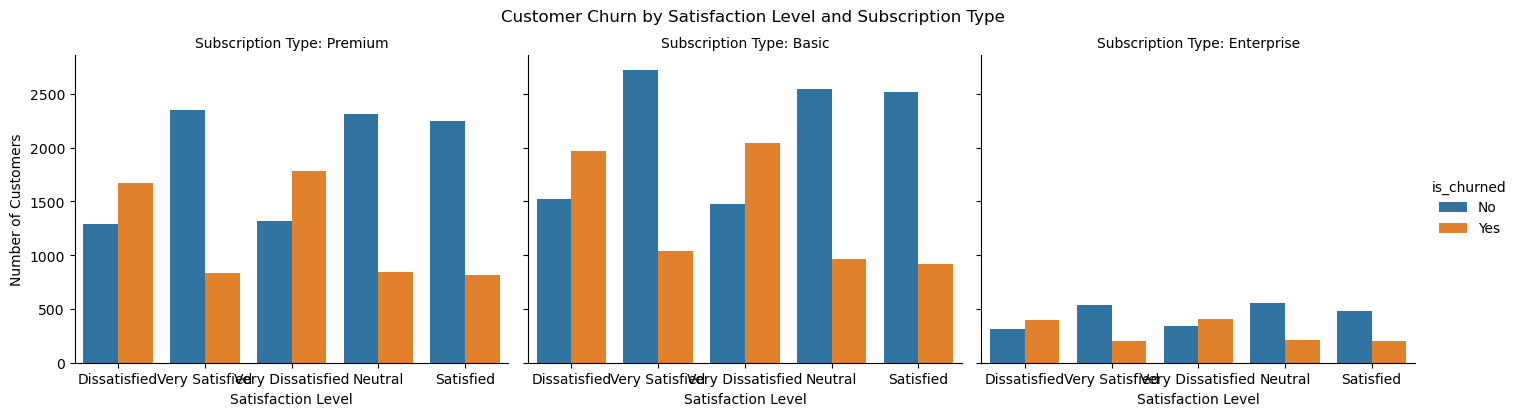

In [25]:



ch_data = ch[
    ch['subscription_type'].notna() &
    (ch['subscription_type'].str.strip().str.lower() != 'unknown')
]

g = sns.catplot(
    data=ch_data,
    x='satisfaction_level',
    hue='is_churned',
    col='subscription_type',
    kind='count',
    col_wrap=3,
    height=4,
    aspect=1.2
)

g.set_axis_labels('Satisfaction Level', 'Number of Customers')
g.set_titles('Subscription Type: {col_name}')
g.fig.suptitle(
    'Customer Churn by Satisfaction Level and Subscription Type',
    y=1.03
)

plt.show()


#### Customers with Dissatisfied and Very Dissatisfied satisfaction levels show higher churn counts, while other satisfaction groups have more non-hurned customers.”

### Customer Churn Reasons by Customer segment
To identify the common reasons for customer churn across different customer segments.

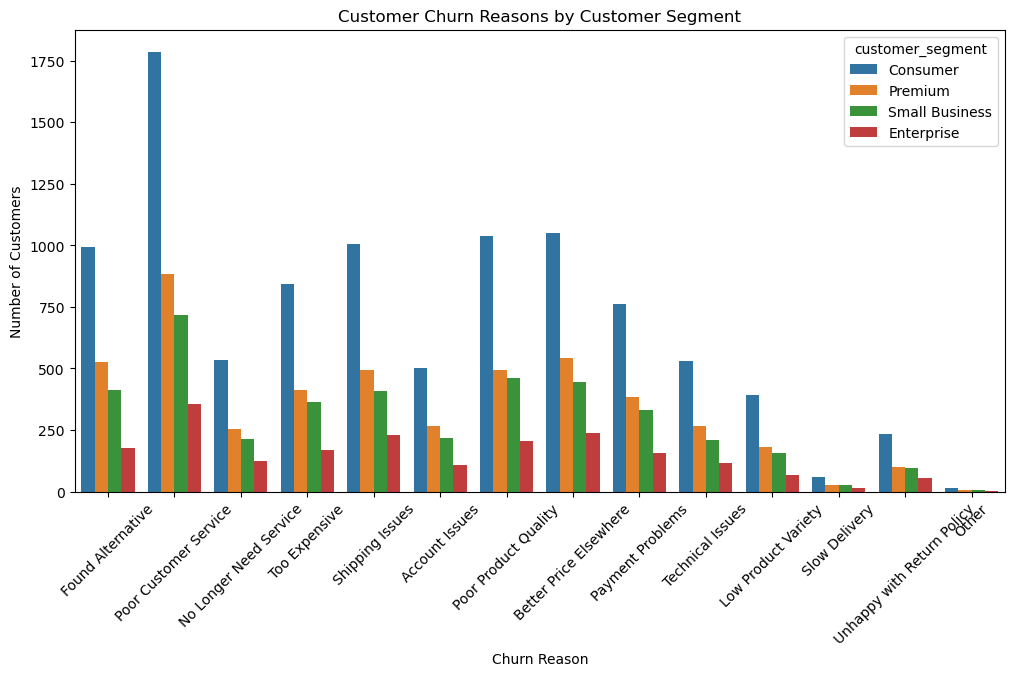

In [26]:
plt.figure(figsize=(12,6))

sns.countplot(data=ch[ch['is_churned'] == 'Yes'],
              x='churn_reason',
              hue='customer_segment')

plt.title('Customer Churn Reasons by Customer Segment')
plt.xlabel('Churn Reason')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

#### Among all customer segments, Consumer has the highest number of churn cases across most churn reasons, followed by Premium and Small Business, while Enterprise has the lowest number of churn cases.”

# 🔑 Key Insights

### Q1: What is the overall customer churn situation?
Key Insights:
- The dataset contains 50,000 customer records.
- Approximately 41.3% of customers have churned.
- Around 58.7% of customers are still active.
- This shows that the company is losing a considerable number of customers.
### Q2: Which customer segment has the highest churn rate?
Key Insights:
- Consumer segment has the highest churn rate at 43.64%.
- Small Business customers have a churn rate of 40.64%.
- Enterprise customers have a churn rate of 39.30%.
- Premium customers have the lowest churn rate at 38.50%.
### Q3: Which subscription type has the highest churn rate?
Key Insights:
- Basic subscription has the highest churn rate at 39.11%.
- Enterprise subscription follows with 38.99%.
- Premium subscription has the lowest churn rate at 38.42%.
- The difference between subscription types is relatively small.
Note: Unknown subscription values were excluded from this comparison because their actual subscription type is unavailable.
### Q4: How do support tickets relate to customer churn?
Key Insights:
- Customers with 11–15 support tickets show a churn rate of approximately 49%.
- This indicates that customers who raise more support tickets may be more likely to leave the company.
- Improving customer support and resolving repeated complaints may help reduce churn.
### Q5: What are the main reasons for customer churn?
Key Insights:
- Poor Customer Service is the most common reason for customer churn.
- Better Price Elsewhere is another major reason.
- Poor Product Quality and Found Alternatives are also important reasons.
- This suggests that improving customer service and product quality may help retain customers.

# ✅ Recommendations

#### Based on the overall customer churn analysis, the following business recommendations can help the company improve customer retention and reduce customer loss.
1. **Improve Customer Service:** Provide better customer support and resolve customer complaints quickly to improve customer satisfaction.

2. **Strengthen Customer Retention:** Identify customers who are likely to leave and provide special offers, discounts, and loyalty rewards.

3. **Understand Customer Needs:** Collect regular customer feedback and improve services based on their expectations.

4. **Review Subscription Plans:** Evaluate subscription pricing and benefits to make plans more attractive and competitive.

5. **Monitor Customer Complaints:** Track repeated support tickets and take necessary actions to prevent customer dissatisfaction.

6. **Improve Product Quality:** Focus on product improvements to meet customer expectations and reduce churn.

7. **Regular Churn Monitoring:** Monitor customer churn rates regularly to identify problems early and take corrective actions.